In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # 0 = all logs, 1 = filter INFO, 2 = filter INFO & WARNING, 3 = only FATAL errors

import tensorflow as tf

In [2]:
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory growth enabled on:", gpus[0].name)
    except RuntimeError as e:
        print("Memory growth setup error:", e)

Memory growth enabled on: /physical_device:GPU:0


In [3]:
import os
import json
import pickle
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.applications.densenet import DenseNet201, preprocess_input
from tensorflow.keras.models import Model

# File paths
DATA_DIR = "../data"
MODELS_DIR = "../models"
IMAGES_DIR = os.path.join(DATA_DIR, "Images")
MODEL_PATH = os.path.join(MODELS_DIR, "best_model.keras")
FEATURES_PATH = os.path.join(DATA_DIR, "features.pkl")
CAPTIONS_PATH = os.path.join(DATA_DIR, "cleaned_captions.json")
WORD_TO_IDX_PATH = os.path.join(DATA_DIR, "word_to_idx.json")
METADATA_PATH = os.path.join(DATA_DIR, "dataset_metadata.json")
TEST_SPLIT_PATH = os.path.join(DATA_DIR, "Flickr_8k.testImages.txt")

# 1. Load trained model
print("Loading trained captioning model...")
caption_model = load_model(MODEL_PATH)

# 2. Load mappings and metadata
with open(WORD_TO_IDX_PATH, "r", encoding="utf-8") as f:
    word_to_idx = json.load(f)

idx_to_word = {int(v): k for k, v in word_to_idx.items()}

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata = json.load(f)
max_seq_len = metadata["max_seq_len"]

# 3. Load precomputed features and test image names
with open(FEATURES_PATH, "rb") as f:
    features = pickle.load(f)

with open(CAPTIONS_PATH, "r", encoding="utf-8") as f:
    ground_truth_captions = json.load(f)

with open(TEST_SPLIT_PATH, "r", encoding="utf-8") as f:
    test_image_names = [line.strip() for line in f if line.strip()]

print(f"Model and assets loaded successfully!")
print(f"Test set images available: {len(test_image_names)}")

Loading trained captioning model...


/home/akarsh/projects/visiontalk/.venv/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 30 variables whereas the saved optimizer has 34 variables. 
  saveable.load_own_variables(store)


Model and assets loaded successfully!
Test set images available: 1091


In [4]:
def generate_caption(model, img_features, word_to_idx, idx_to_word, max_len):
    in_text = "startseq"
    img_features = np.expand_dims(img_features, axis=0)

    for _ in range(max_len):
        sequence = [word_to_idx.get(w, word_to_idx.get("<unk>")) for w in in_text.split()]
        sequence = pad_sequences([sequence], maxlen=max_len, padding="post")

        y_pred = model.predict(
            {"image_input": img_features, "caption_input": sequence},
            verbose=0
        )
        predicted_idx = int(np.argmax(y_pred[0]))
        predicted_word = idx_to_word.get(predicted_idx, None)

        # Stop condition: reached end token, unrecognized index, or loop repeats
        if predicted_word is None or predicted_word in ["endseq", "<unk>", "<pad>"]:
            break

        in_text += " " + predicted_word

    return in_text.replace("startseq", "").strip()

In [5]:
import random
import numpy as np
import tensorflow as tf
from nltk.translate.bleu_score import corpus_bleu
from tqdm import tqdm

NUM_SAMPLES = 150
random.seed(42)

valid_candidates = [
    img for img in test_image_names 
    if img in features and img in ground_truth_captions
]
eval_samples = random.sample(valid_candidates, min(NUM_SAMPLES, len(valid_candidates)))

start_word = "startseq" if "startseq" in word_to_idx else ("start" if "start" in word_to_idx else "<start>")
end_word = "endseq" if "endseq" in word_to_idx else ("end" if "end" in word_to_idx else "<end>")
start_idx = word_to_idx[start_word]
end_idx = word_to_idx.get(end_word, None)

actual_captions = []
predicted_captions = []

print(f"Evaluating BLEU scores across {len(eval_samples)} test samples on GPU...")

with tf.device("/GPU:0"):
    for img_name in tqdm(eval_samples):
        # 1. Clean ground truth references
        refs = [
            ref.replace("startseq", "").replace("endseq", "").replace("start", "").replace("end", "").strip().split()
            for ref in ground_truth_captions[img_name]
        ]
        actual_captions.append(refs)

        # 2. Fast tensor prediction on RTX 3050
        img_feat = tf.convert_to_tensor(np.expand_dims(features[img_name], axis=0), dtype=tf.float32)
        seq = [start_idx]
        pred_words = []

        for _ in range(max_seq_len):
            pad_len = max_seq_len - len(seq)
            if pad_len > 0:
                padded = np.pad(seq, (pad_len, 0), mode="constant", constant_values=0)
            else:
                padded = np.array(seq[-max_seq_len:])
                
            seq_tensor = tf.convert_to_tensor(np.expand_dims(padded, axis=0), dtype=tf.int32)

            preds = caption_model([img_feat, seq_tensor], training=False)
            yhat = int(np.argmax(preds[0]))

            if yhat == end_idx:
                break

            word = idx_to_word.get(yhat, None)
            if word is None or word == end_word:
                break

            # Repetition penalty break
            if len(pred_words) >= 2 and pred_words[-1] == word and pred_words[-2] == word:
                break

            pred_words.append(word)
            seq.append(yhat)

        predicted_captions.append(pred_words)

# Calculate BLEU-1 to BLEU-4
bleu1 = corpus_bleu(actual_captions, predicted_captions, weights=(1.0, 0, 0, 0))
bleu2 = corpus_bleu(actual_captions, predicted_captions, weights=(0.5, 0.5, 0, 0))
bleu3 = corpus_bleu(actual_captions, predicted_captions, weights=(0.33, 0.33, 0.33, 0))
bleu4 = corpus_bleu(actual_captions, predicted_captions, weights=(0.25, 0.25, 0.25, 0.25))

print("\n--- Model Benchmark Results ---")
print(f"BLEU-1: {bleu1:.4f}")
print(f"BLEU-2: {bleu2:.4f}")
print(f"BLEU-3: {bleu3:.4f}")
print(f"BLEU-4: {bleu4:.4f}")

Evaluating BLEU scores across 150 test samples on GPU...


100%|██████████| 150/150 [04:54<00:00,  1.96s/it]


--- Model Benchmark Results ---
BLEU-1: 0.2589
BLEU-2: 0.1345
BLEU-3: 0.0634
BLEU-4: 0.0308


In [6]:
from nltk.translate.bleu_score import corpus_bleu
from tqdm import tqdm
import tensorflow as tf

actual_captions = []
predicted_captions = []

print(f"Evaluating BLEU scores across all {len(test_image_names)} test images on GPU...")

with tf.device("/GPU:0"):
    for img_name in tqdm(test_image_names):
        if img_name not in features or img_name not in ground_truth_captions:
            continue

        # Clean ground truth references (strip start and end markers)
        refs = [
            ref.replace("startseq", "").replace("endseq", "")
               .replace("start", "").replace("end", "")
               .strip().split()
            for ref in ground_truth_captions[img_name]
        ]

        # Generate prediction
        img_feat = features[img_name]
        candidate = generate_caption(caption_model, img_feat, word_to_idx, idx_to_word, max_seq_len)
        candidate_tokens = candidate.split()

        actual_captions.append(refs)
        predicted_captions.append(candidate_tokens)

# Compute corpus BLEU-1 to BLEU-4
bleu_1 = corpus_bleu(actual_captions, predicted_captions, weights=(1.0, 0, 0, 0))
bleu_2 = corpus_bleu(actual_captions, predicted_captions, weights=(0.5, 0.5, 0, 0))
bleu_3 = corpus_bleu(actual_captions, predicted_captions, weights=(0.33, 0.33, 0.33, 0))
bleu_4 = corpus_bleu(actual_captions, predicted_captions, weights=(0.25, 0.25, 0.25, 0.25))

print("\n--- Full Test Set Evaluation Results ---")
print(f"BLEU-1: {bleu_1:.4f}")
print(f"BLEU-2: {bleu_2:.4f}")
print(f"BLEU-3: {bleu_3:.4f}")
print(f"BLEU-4: {bleu_4:.4f}")

Evaluating BLEU scores across all 1091 test images on GPU...


100%|██████████| 1091/1091 [15:35<00:00,  1.17it/s]



--- Full Test Set Evaluation Results ---
BLEU-1: 0.5419
BLEU-2: 0.3298
BLEU-3: 0.2001
BLEU-4: 0.1246


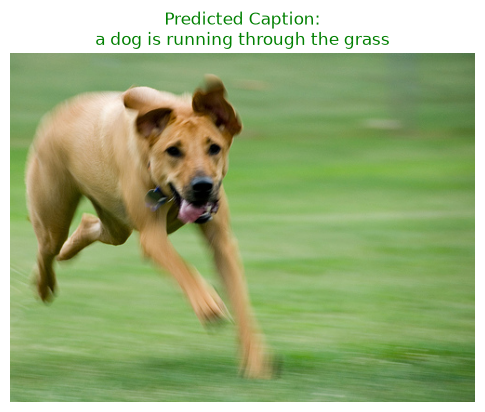

'a dog is running through the grass'

In [7]:
# Load feature extractor model
base_densenet = DenseNet201(weights="imagenet")
feature_extractor = Model(inputs=base_densenet.inputs, outputs=base_densenet.layers[-2].output)

def caption_any_image(image_path):
    # Preprocess image
    img = load_img(image_path, target_size=(224, 224))
    img_arr = img_to_array(img)
    img_arr = np.expand_dims(img_arr, axis=0)
    img_arr = preprocess_input(img_arr)

    # Extract 1920-d visual feature vector
    live_features = feature_extractor.predict(img_arr, verbose=0).reshape(-1)

    # Decode caption
    caption = generate_caption(caption_model, live_features, word_to_idx, idx_to_word, max_seq_len)

    # Display image with caption
    original_img = load_img(image_path)
    plt.figure(figsize=(6, 6))
    plt.imshow(original_img)
    plt.axis("off")
    plt.title(f"Predicted Caption:\n{caption}", fontsize=12, color="green")
    plt.show()

    return caption

# Test with any image from your Images folder
sample_path = os.path.join(IMAGES_DIR, test_image_names[0])
caption_any_image(sample_path)